# Ventaneo HU y realce de contraste

Define el preprocesamiento de intensidades que usan los notebooks siguientes y lo justifica visualmente con el caso 001:

- `load_mha`: lee un volumen `.mha` en orden `(z, y, x)` con su spacing.
- `apply_hu_window`: ventana osea (centro 400 HU, ancho 1800 HU) normalizada a `[0, 1]`.
- `enhance_bone_contrast`: realce Otsu + CLAHE solo dentro del hueso.

**Entradas:** `splits/dataset.csv` (notebook 01) y `data_mha/`.

## 1. Configuracion

Rutas relativas a la raiz del repositorio y lectura de los archivos que generan los notebooks anteriores. Las definiciones compartidas se cargan por nombre desde el notebook donde viven (`definiciones_notebooks.cargar_definiciones`), sin ejecutar sus celdas de prueba.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import SimpleITK as sitk

# Raiz del repositorio: funciona si el kernel arranca en notebooks/ o en la raiz.
BASE_DIR = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "requirements.txt").is_file())
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))  # modulos .py del proyecto

SPLITS_DIR = BASE_DIR / "splits"

def to_repo_relative(path):
    """Guarda rutas portables dentro del repositorio."""
    path = Path(path)
    try:
        return path.relative_to(BASE_DIR).as_posix()
    except ValueError:
        return path.as_posix()


def resolve_repo_path(path):
    """Permite leer rutas relativas o absolutas sin romper compatibilidad."""
    path = Path(path)
    if path.is_absolute():
        return path
    return BASE_DIR / path

# Dataset curado y splits generados por 01_dataset_splits.ipynb
df = pd.read_csv(SPLITS_DIR / "dataset.csv", dtype={"case_id": str})

## 2. Ventaneo HU para visualizacion de hueso

Se define una ventana osea aproximada usando centro 400 HU y ancho 1800 HU. El objetivo es redistribuir intensidades para resaltar hueso y justificar el preprocesamiento con valores HU.

In [2]:
def load_mha(path):
    image = sitk.ReadImage(str(resolve_repo_path(path)))
    volume = sitk.GetArrayFromImage(image).astype(np.float32)  # orden (z, y, x)
    spacing = tuple(float(value) for value in image.GetSpacing())  # (x, y, z) mm
    return volume, spacing


def apply_hu_window(volume, window_center=400, window_width=1800):
    low = window_center - window_width / 2
    high = window_center + window_width / 2
    windowed = np.clip(volume, low, high)
    windowed = (windowed - low) / (high - low)
    return windowed

# prueba rapida sobre un caso MHA
volume, spacing = load_mha(df.loc[0, "image_path"])
windowed = apply_hu_window(volume)
print(f"Caso {df.loc[0, 'case_id']}: spacing={spacing}, "
      f"rango original=({volume.min():.1f}, {volume.max():.1f}), "
      f"rango ventaneado=({windowed.min():.2f}, {windowed.max():.2f})")

Caso 001: spacing=(0.78125, 0.78125, 0.800000011920929), rango original=(-1023.0, 2775.0), rango ventaneado=(0.00, 1.00)


## 3. Comparacion visual antes y despues del ventaneo

Se muestra un corte del caso 001 sin ventanear y con ventana osea. Esta evidencia ayuda a explicar por que el ventaneo mejora la discriminacion visual del hueso.

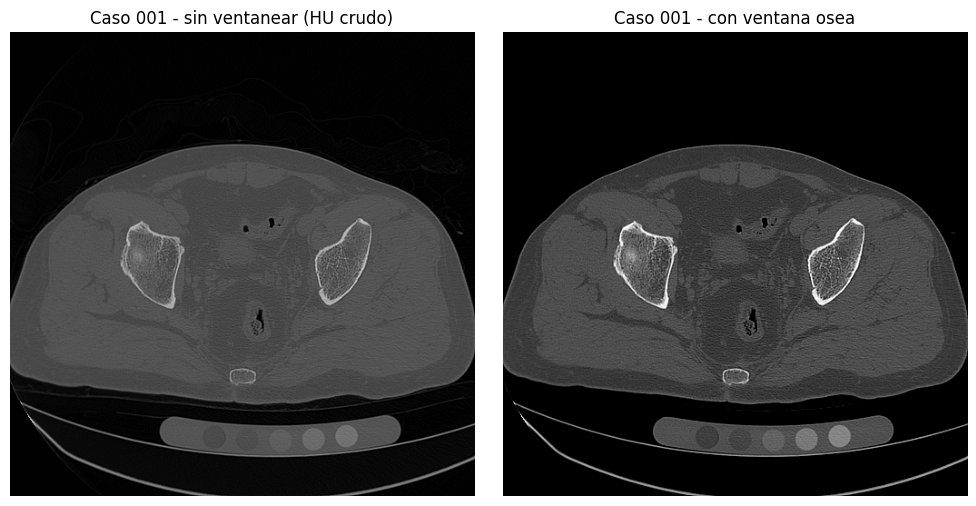

In [3]:
case_id = "001"
row = df[df["case_id"] == case_id].iloc[0]

volume, spacing = load_mha(row["image_path"])
windowed = apply_hu_window(volume)

# SimpleITK entrega el volumen en orden (z, y, x)
mid_slice = volume.shape[0] // 2

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(volume[mid_slice], cmap="gray")
axes[0].set_title(f"Caso {case_id} - sin ventanear (HU crudo)")
axes[0].axis("off")

axes[1].imshow(windowed[mid_slice], cmap="gray", vmin=0, vmax=1)
axes[1].set_title(f"Caso {case_id} - con ventana osea")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [4]:
from skimage.filters import threshold_otsu
from skimage.exposure import equalize_adapthist

def enhance_bone_contrast(image_hu_window, clahe_clip_limit=0.01, clahe_nbins=256):
    """
    Toma una imagen YA ventaneada con apply_hu_window (rango [0,1]) y:
    1. Calcula un umbral de Otsu (excluyendo fondo/aire) para aislar donde hay hueso real.
    2. Aplica CLAHE solo dentro de esa zona, dejando el resto atenuado.
    Esto evita que el realce de contraste "invente" detalle en tejido blando.
    """
    nonzero_vals = image_hu_window[image_hu_window > 0]
    if nonzero_vals.size == 0:
        return image_hu_window  # corte vacío (solo aire), no hay nada que realzar

    otsu_thresh = threshold_otsu(nonzero_vals)
    bone_mask = image_hu_window > otsu_thresh

    clahe_full = equalize_adapthist(image_hu_window, clip_limit=clahe_clip_limit, nbins=clahe_nbins)

    # Donde hay hueso: usa CLAHE. Donde no: imagen original atenuada (sin inventar contraste)
    result = np.where(bone_mask, clahe_full, image_hu_window * 0.3)
    return result.astype(np.float32)

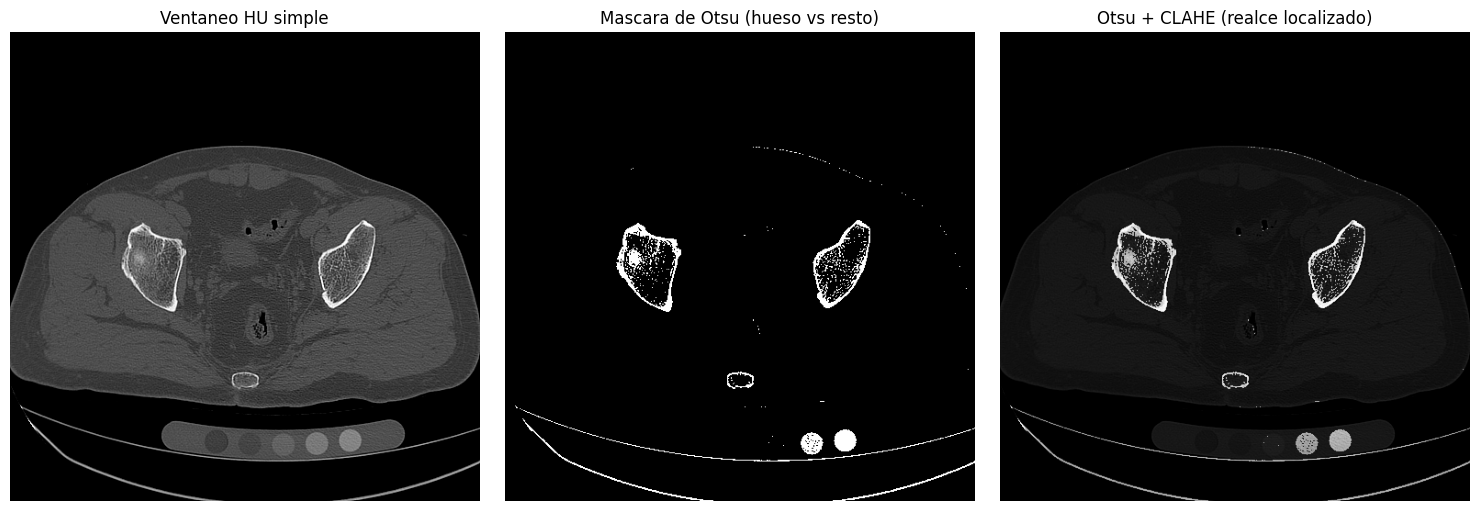

In [5]:
mid_slice_idx = volume.shape[0] // 2
imagen_simple = windowed[mid_slice_idx]
imagen_realzada = enhance_bone_contrast(imagen_simple)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(imagen_simple, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Ventaneo HU simple")
axes[1].imshow(imagen_simple > threshold_otsu(imagen_simple[imagen_simple > 0]), cmap="gray")
axes[1].set_title("Mascara de Otsu (hueso vs resto)")
axes[2].imshow(imagen_realzada, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Otsu + CLAHE (realce localizado)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

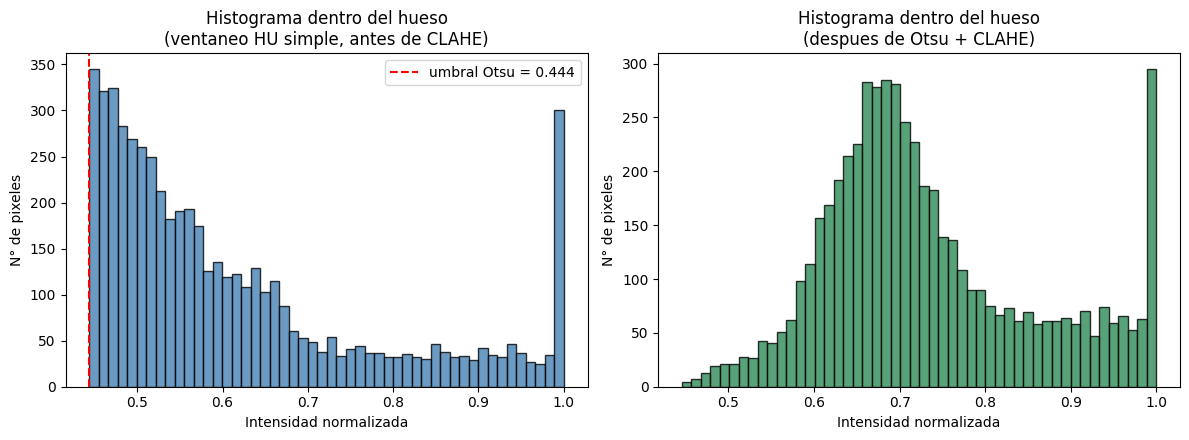

Antes  -> media=0.616, std=0.162, rango=(0.444, 1.000)
Despues -> media=0.734, std=0.125, rango=(0.446, 1.000)


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Histograma de la zona de hueso ANTES de CLAHE (solo ventaneo + Otsu como mascara)
otsu_thresh_hist = threshold_otsu(imagen_simple[imagen_simple > 0])
bone_mask_hist = imagen_simple > otsu_thresh_hist

valores_antes = imagen_simple[bone_mask_hist]
valores_despues = imagen_realzada[bone_mask_hist]

axes[0].hist(valores_antes, bins=50, color="steelblue", alpha=0.8, edgecolor="black")
axes[0].set_title("Histograma dentro del hueso\n(ventaneo HU simple, antes de CLAHE)")
axes[0].set_xlabel("Intensidad normalizada")
axes[0].set_ylabel("N° de pixeles")
axes[0].axvline(otsu_thresh_hist, color="red", linestyle="--", label=f"umbral Otsu = {otsu_thresh_hist:.3f}")
axes[0].legend()

axes[1].hist(valores_despues, bins=50, color="seagreen", alpha=0.8, edgecolor="black")
axes[1].set_title("Histograma dentro del hueso\n(despues de Otsu + CLAHE)")
axes[1].set_xlabel("Intensidad normalizada")
axes[1].set_ylabel("N° de pixeles")

plt.tight_layout()
plt.show()

print(f"Antes  -> media={valores_antes.mean():.3f}, std={valores_antes.std():.3f}, "
      f"rango=({valores_antes.min():.3f}, {valores_antes.max():.3f})")
print(f"Despues -> media={valores_despues.mean():.3f}, std={valores_despues.std():.3f}, "
      f"rango=({valores_despues.min():.3f}, {valores_despues.max():.3f})")